In [24]:
#####     factors of bias     #####
import numpy as np
from joblib import load, dump
from osgeo import gdal
gdal.UseExceptions()

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap, BoundaryNorm
from matplotlib.patches import Patch, Circle

import cartopy.crs as ccrs
lat, lon = np.arange(-90, 90.1, 1), np.arange(0, 360.1, 1)

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF

from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import shap
from _ShapScatter import shap_scatter

def PlotImg(data:np.ndarray, title:str="", cmap:str="RdBu_r",
            vmin:float=None, vmax:float=None, cbar:bool=True):
    ax = plt.axes(projection=ccrs.Robinson())
    ax.coastlines(color="gray")
    img = ax.pcolormesh(lon, lat, data, cmap=cmap, vmin=vmin, vmax=vmax,
                        transform=ccrs.PlateCarree(), shading="flat")
    ax.set_title(title)
    if cbar:
        plt.colorbar(img, ax=ax, shrink=0.8, pad=0.05, orientation="horizontal")
    plt.show()
    plt.close()

def CheckVIF(data:np.ndarray, names:list, vif_thr:float=10.):
    """Check VIF of each variable in data,
    and delete the variable with highest VIF > threshold
    """
    X = sm.add_constant(data)  ###
    vifs = [VIF(X, i) for i in range(1, X.shape[1])]
    max_vif, idx = np.max(vifs), np.argmax(vifs)
    if max_vif < vif_thr:
        print(f"END. Remain Vars: {len(names)}")
        return True, data, names
    else:
        print(f"Var {names[idx]} eliminated. VIF: {max_vif:.2f}")
        data_ = np.delete(data, idx, axis=1)
        names_ = np.delete(names, idx, axis=0)
        return False, data_, names_

def LinearRegTest(X:np.ndarray, Y:np.ndarray):
    print("Linear Regression")
    Model = LinearRegression()
    Model.fit(X, Y)
    #print(Model.coef_)
    #print(Model.intercept_)
    R2 = Model.score(X, Y)
    y_pred = Model.predict(X)
    RMSE = np.sqrt(np.mean((y_pred - Y)**2))
    print(f"R2 = {R2:.4f},  RMSE = {RMSE:.4f}")

### ---------- Load Data ---------- ###
ESA_data:np.ndarray = load("./Data/ESACCI_mean.joblib") # (lat, lon)
CMIP_set:dict = load("./Data/CMIPdata_5yr.joblib") # cVeg & treeFrac
CMIP_list = [i for (i,_) in CMIP_set.values()]
CMIP_data = np.stack(CMIP_list, axis=0) # CMIP data (N, lat, lon)
modelNum = len(CMIP_set) # 模型数量：30
modelNames = list(CMIP_set.keys())
print(f"Models: {modelNum}")

ValidMask = load("./Data/Masks/validmask.joblib")
TreeMask = load("./Data/Masks/treemask.joblib")
MASK = ValidMask & TreeMask ###

CMIP_mean = np.nanmean(CMIP_data, axis=0)
Bias = CMIP_mean - ESA_data ### (lat, lon)
Bias[~MASK] = np.nan

clim_name = ["Tmean", "MDR", "ISO", "Tssn", "Tmax", "Tmin", "TAR", "TWeQ", "TDrQ", "TWaQ", "TCoQ",
             "Prec", "PWM", "PDM", "Pssn", "PWeQ", "PDrQ", "PWaQ", "PCoQ"]
var_clim = load("./Data/vars/VarClim.joblib")
var_soil1 = load("./Data/vars/VarSoil_face.joblib")
var_soil2 = load("./Data/vars/VarSoil_sub.joblib")
var_veg = load("./Data/vars/VarVeg.joblib")

vars_list, vars_name = [], []
vars_list.extend(var_clim.values())
vars_list.extend(var_soil1.values())
vars_list.extend(var_soil2.values())
vars_list.extend(var_veg.values())
vars_name.extend(var_clim.keys())
vars_name.extend(var_soil1.keys())
vars_name.extend(var_soil2.keys())
vars_name.extend(var_veg.keys())

for i in range(len(clim_name)):
    vars_name[i] = vars_name[i] + " (" + clim_name[i] + ")"
num_clim, num_soil, num_veg = len(var_clim), len(var_soil1)+len(var_soil2), len(var_veg)
print(f"Variables: {len(vars_name)}")
#print(vars_name)
# Clim: 19,  Soil: 26,  Veg: 3

for arr in vars_list:
    MASK = MASK & (~np.isnan(arr))

Variables = np.stack(vars_list, axis=0) # (V, lat, lon)
Variables = Variables[:, MASK]  # (V, N)

### ---------- Check VIF ---------- ###
if False:
    print("\nVariance Inflation Factor (VIF) Check")
    selected = vars_name.copy()
    X = np.transpose(Variables)  # (N, V)
    for iters in range(len(vars_name)):
        print(f"Iter {iters+1}:", end=" ")
        pass_, X, selected = CheckVIF(X, selected)
        if pass_:
            print(selected); break
        else: continue
    Variables = np.transpose(X)  # (V', N)
    num_clim_ = np.sum(np.isin(selected, vars_name[:num_clim]))
    num_soil_ = np.sum(np.isin(selected, vars_name[num_clim:num_clim+num_soil]))
    num_veg_ = np.sum(np.isin(selected, vars_name[num_clim+num_soil:]))
    num_clim, num_soil, num_veg = num_clim_, num_soil_, num_veg_
else:
    selected = vars_name

print(f"Clim: {num_clim},  Soil: {num_soil},  Veg: {num_veg}")
# Clim: 19,  Soil: 26,  Veg: 3
# Clim: 8,  Soil: 14,  Veg: 3

Models: 30
Variables: 48
Clim: 19,  Soil: 26,  Veg: 3


C:\Users\17596\AppData\Local\Temp\ipykernel_9484\2944796127.py:76: RuntimeWarning: Mean of empty slice
  CMIP_mean = np.nanmean(CMIP_data, axis=0)


In [ ]:
### ---------- Regression ---------- ###
print("\nRegression")
X, Y = np.transpose(Variables), Bias[MASK]
print(X.shape, Y.shape)
#X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

#LinearRegTest(X, Y)
    
if False:
    #layer, node = 10, 100
    #kwargs = {"activation":"relu", "solver":"adam", "max_iter":1000, "early_stopping":True}
    #Model = MLPRegressor(hidden_layer_sizes=[node for i in range(layer)], **kwargs)
    Model = RandomForestRegressor(n_estimators=200, max_depth=None, n_jobs=4)
    Model.fit(X, Y)
    #dump(Model, "./Model_RF.joblib")
else:
    print("Load RF model")
    Model = load("./Model_RF.joblib")

print(Model)
R2 = Model.score(X, Y)
y_pred = Model.predict(X)
RMSE = np.sqrt(np.mean((y_pred - Y)**2))
print(f"R2 = {R2:.4f},  RMSE = {RMSE:.4f}")

Bias_p = np.full_like(Bias, np.nan)
Bias_p[MASK] = y_pred
#PlotImg(Bias, "Bias (true)", vmin=-60, vmax=60)
#PlotImg(Bias_p, "Bias (pred)", vmin=-60, vmax=60)

if False:
    print("\nSHAP analysis")
    explainer = shap.TreeExplainer(Model, feature_names=selected)
    expl = explainer(X, Y)
    dump(expl, "./shapExpl.joblib")
    print("SHAP explanation completed")
else:
    print("\nLoad SHAP explanation")
    expl:shap.Explanation = load("./shapExpl.joblib")
shap_val = expl.values
print(shap_val.shape)

# Linear Regression
# R2 = 0.5909,  RMSE = 16.4165

# MLP Regression: layer=10, node=100
# R2train≈0.90,  R2test≈0.78
# R2 = 0.926762,  RMSE = 7.7977

# RF Regression: n_estimators=200
# n_estimators=200 test: R2 = 0.7925,  RMSE = 11.5835
# R2 = 0.9749,  RMSE = 4.1715



Regression
(3569, 48) (3569,)
Load RF model
RandomForestRegressor(n_estimators=200, n_jobs=4)
R2 = 0.9749,  RMSE = 4.1715

Load SHAP explanation
(3569, 48)



Feature importance
Clim: 0.4477,  Soil: 0.3479,  Veg: 0.2044
[0.14263346 0.1243952  0.09345885 0.06035909 0.05374602 0.05137522
 0.04642832 0.03194876 0.02650722 0.0224072  0.01823295 0.01600686]


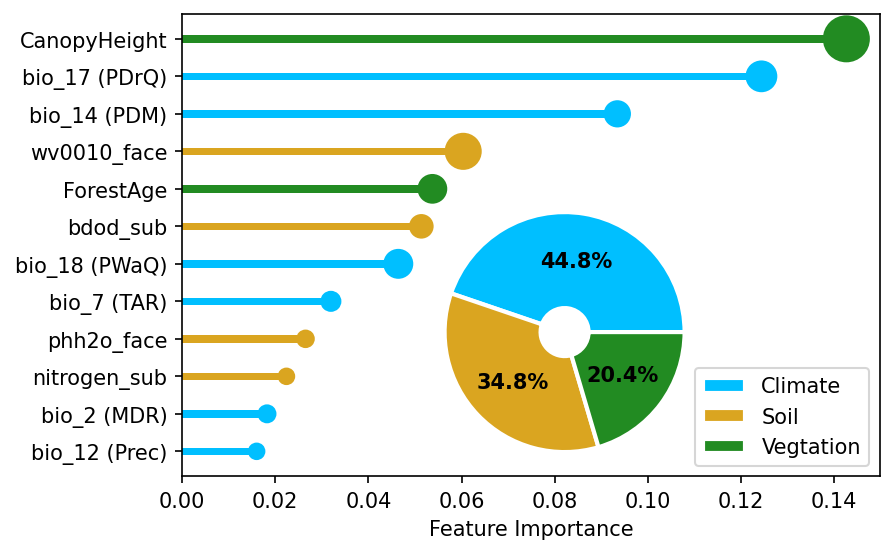

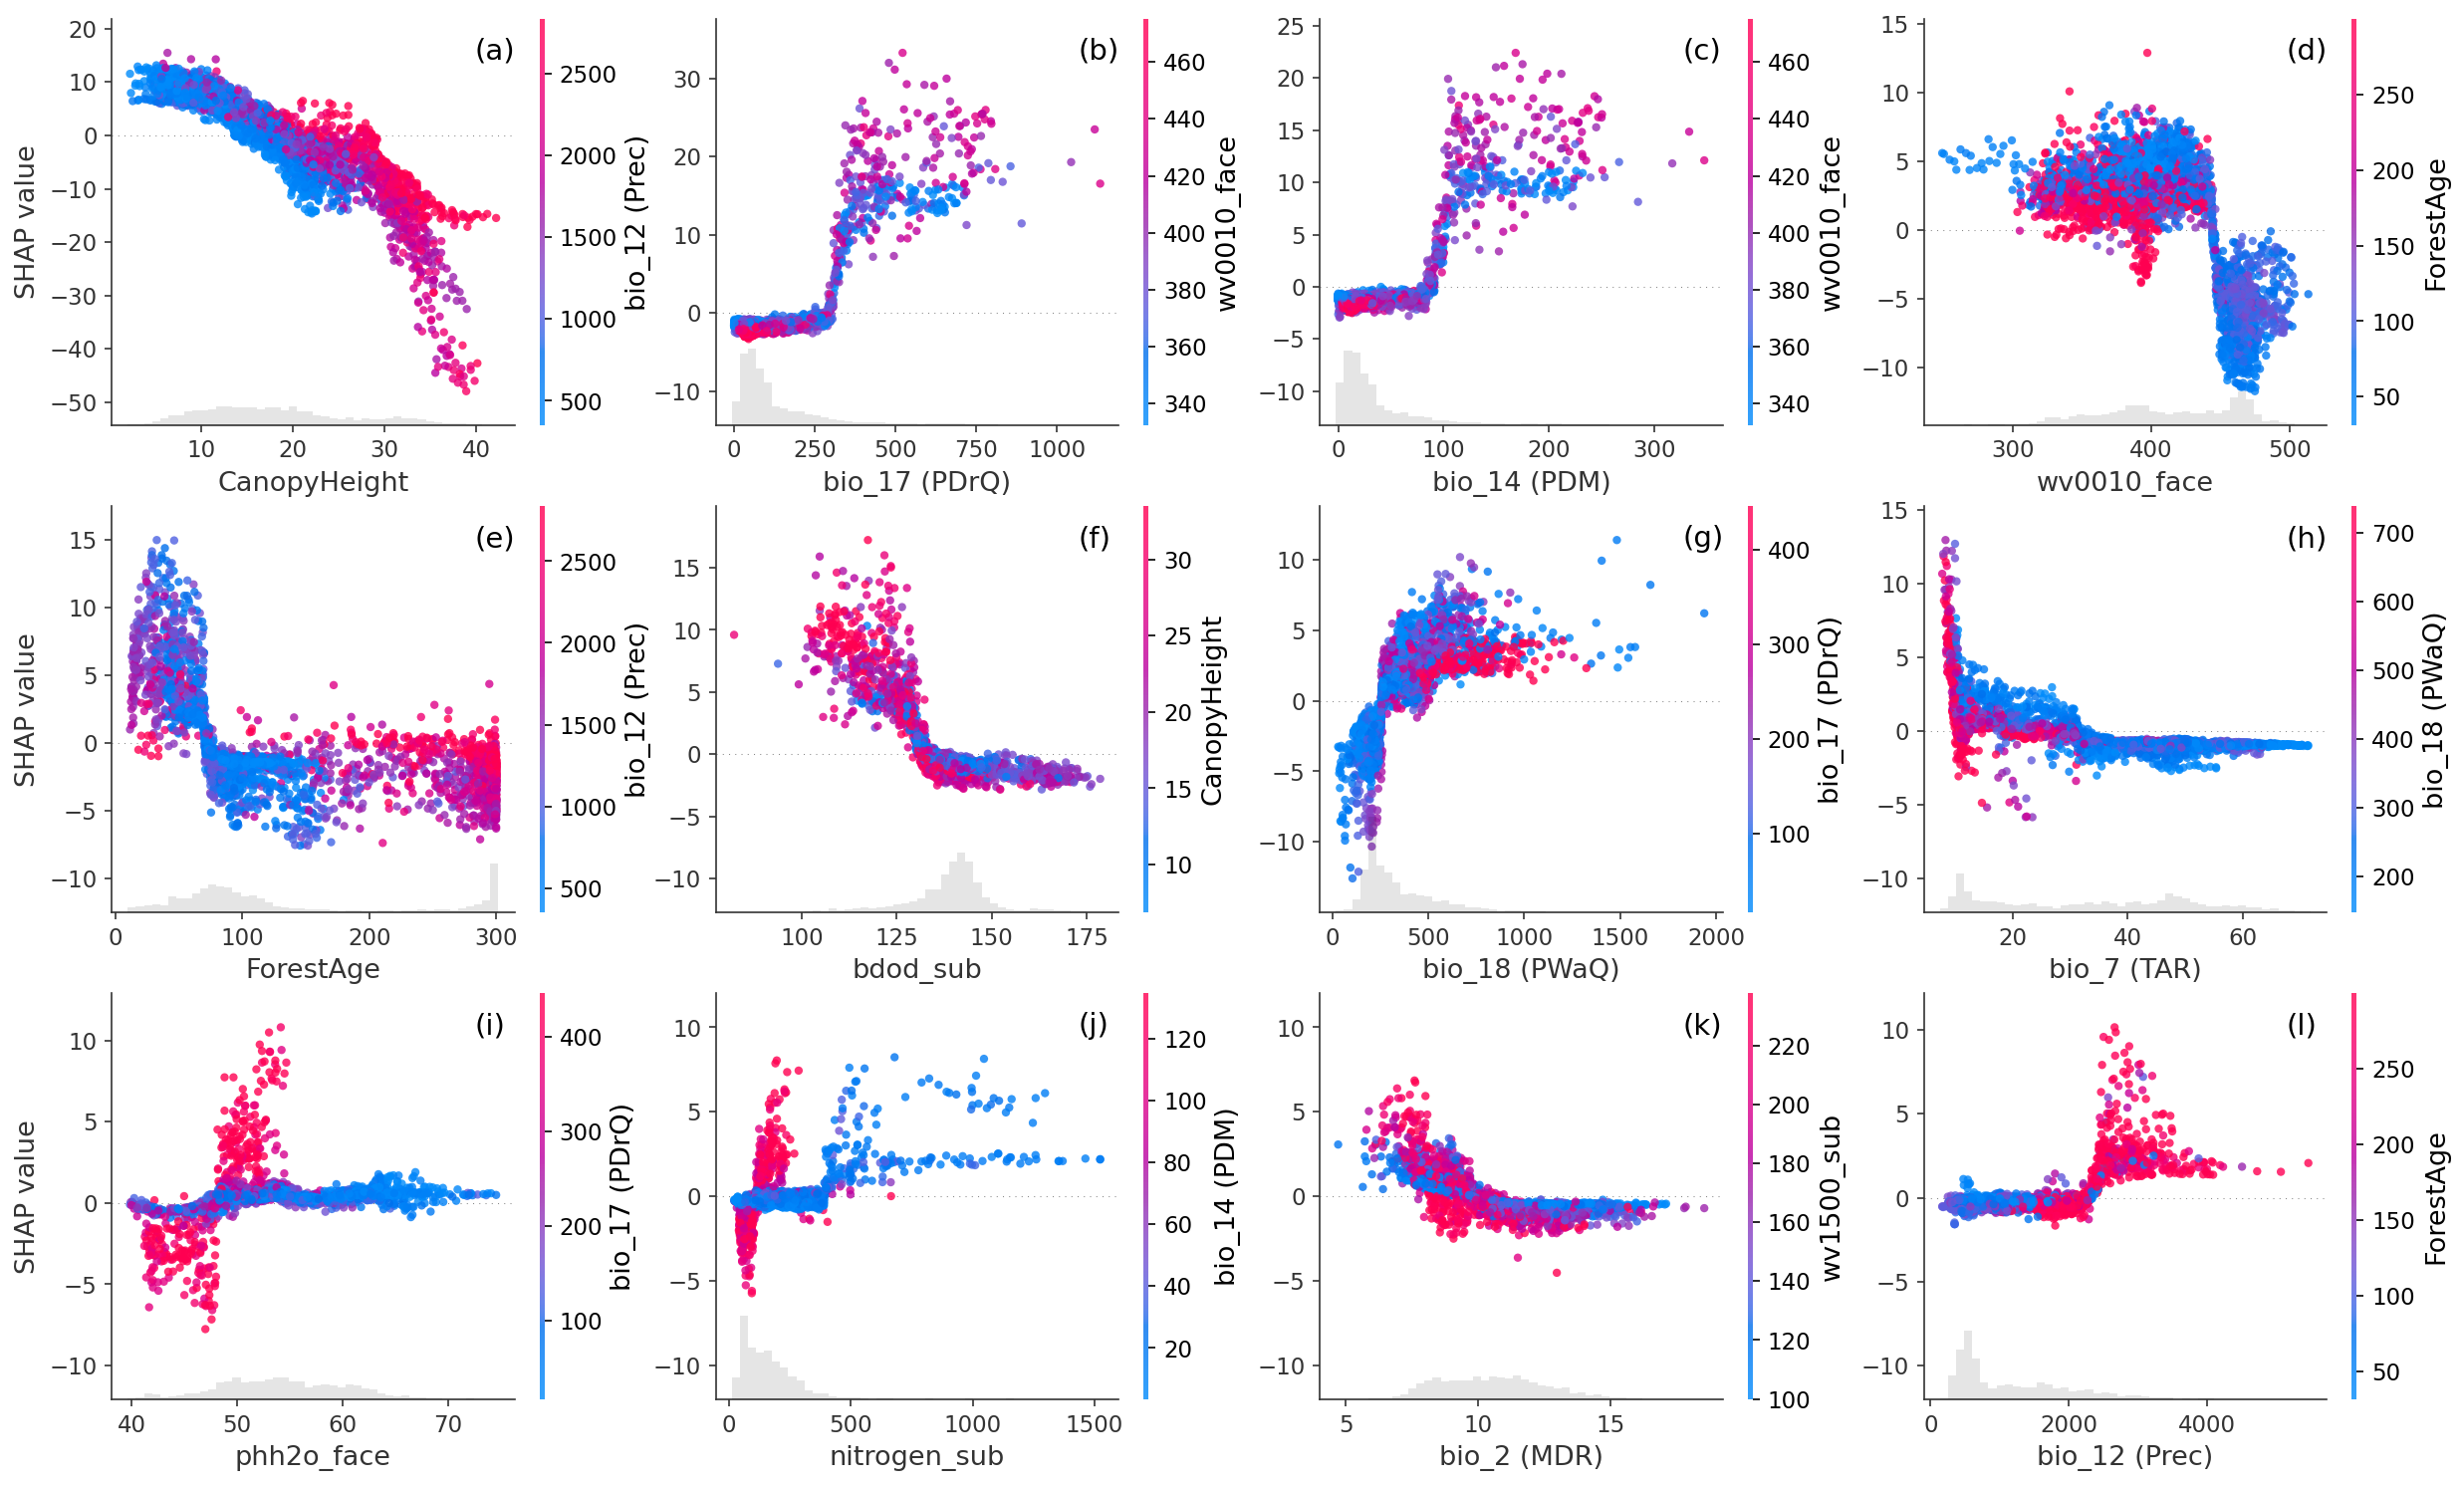

In [ ]:
### ---------- Analysis ---------- ###
color_type = ["deepskyblue", "goldenrod", "forestgreen"]
colors = [color_type[0]] * num_clim + [color_type[1]] * num_soil + [color_type[2]] * num_veg

### feature importances
print("\nFeature importance")
fi = Model.feature_importances_
fi_clim, fi_soil, fi_veg = np.sum(fi[:num_clim]), np.sum(fi[num_clim:num_clim+num_soil]), np.sum(fi[num_clim+num_soil:])
print(f"Clim: {fi_clim:.4f},  Soil: {fi_soil:.4f},  Veg: {fi_veg:.4f}")
# Clim: 0.4477,  Soil: 0.3479,  Veg: 0.2044

show_num = min(12, len(selected))  # 要展示的重要因子数量
pairs = sorted(zip(fi, selected, colors), key=lambda x:x[0], reverse=True)
sort_fi, sort_vn, sort_cl = zip(*pairs[0:show_num])
sort_fi = np.asarray(sort_fi)
print(sort_fi)

# 柱状图
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
ax.barh(range(show_num, 0, -1), sort_fi, height=0.2, color=sort_cl)
ax.set_yticks(range(show_num, 0, -1), sort_vn, fontsize=10)
ax.set_xlabel("Feature Importance", loc="center")

shap_imp = np.array([np.mean(np.abs(expl[:, i].values)) for i in sort_vn])
cal_size = lambda x: (50 * x / np.max(shap_imp) + 10) ** 1.5
ax.scatter(sort_fi, range(show_num, 0, -1), color=sort_cl, s=cal_size(shap_imp))

# 环形图
ax_donut = fig.add_axes([0.3, 0.1, 0.5, 0.5])
ax_donut.set_aspect("equal")
donut_data = [fi_clim, fi_soil, fi_veg]
labels = ["Climate", "Soil", "Vegtation"]
wedges, texts, autotexts = ax_donut.pie(donut_data, colors=color_type, autopct="%.1f%%",
        textprops=dict(fontsize=10, weight="bold"), wedgeprops=dict(width=0.8, edgecolor="w", linewidth=2))
ax.legend(wedges, labels, loc="lower right", frameon=True)
plt.show()
plt.close()

### SHAP
#shap.summary_plot(shap_val, X, feature_names=selected, max_display=12, alpha=0.5, plot_type="dot")
if True:
    sort_vn = list(sort_vn)
    fig, axs = plt.subplots(3, 4, figsize=(20, 12), dpi=150)
    fig = shap_scatter(expl, sort_vn[0:12], fig, axs, color=expl,
                       hist=True, twin_yaxis=False, y_thr=10, alpha=0.8)
    plt.show(fig)



Main factor pattern
2-bio_3 (ISO):  3,  0.1 %
5-bio_6 (Tmin):  8,  0.2 %
6-bio_7 (TAR):  10,  0.3 %
8-bio_9 (TDrQ):  1,  0.0 %
11-bio_12 (Prec):  12,  0.3 %
13-bio_14 (PDM):  2,  0.1 %
16-bio_17 (PDrQ):  304,  8.5 %
17-bio_18 (PWaQ):  49,  1.4 %
23-nitrogen_face:  1,  0.0 %
29-wv0010_face:  974,  27.3 %
32-bdod_sub:  89,  2.5 %
37-ocd_sub:  21,  0.6 %
45-CanopyHeight:  1645,  46.1 %
46-ForestAge:  450,  12.6 %
Climate: 8,  Soil: 4,  Vegetation:2


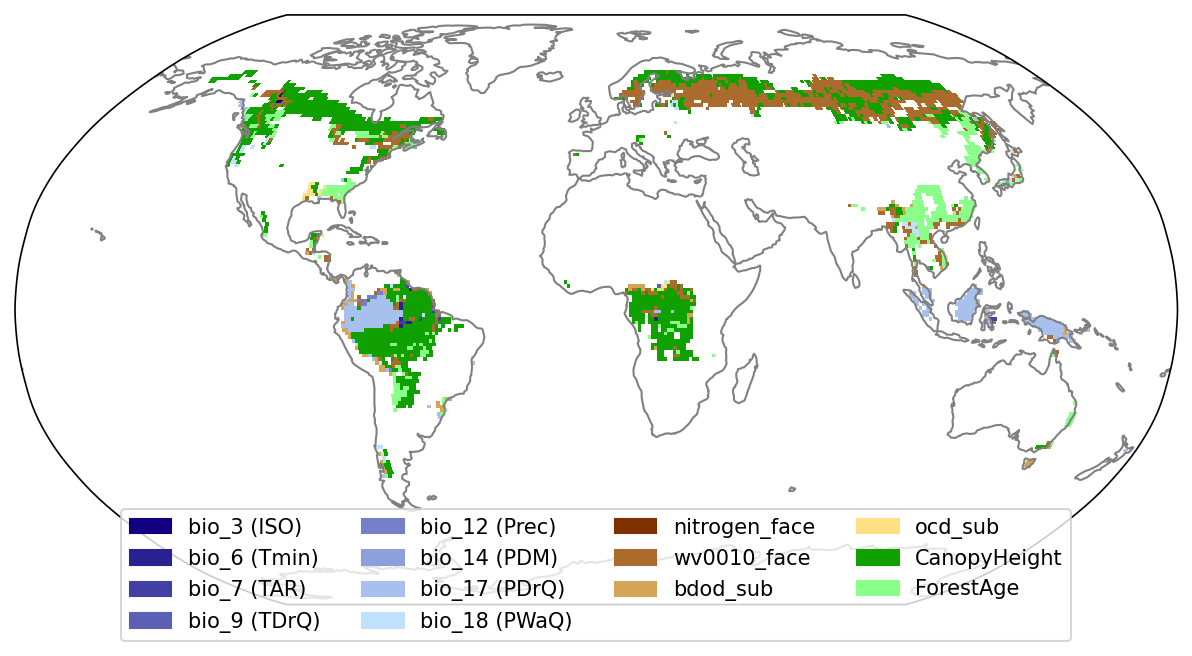

In [ ]:
### ---------- main factor pattern ---------- ###
print("\nMain factor pattern")
#filter = (shap_val * Y[:, None]) > 0; shap_val[~filter] = 0  # filter same direction
main_var = np.argmax(np.abs(shap_val), axis=1)
mainvars, counts = np.unique(main_var, return_counts=True)
mv_clim, mv_soil, mv_veg = [], [], []
for var, count in zip(mainvars, counts):
    print(f"{var}-{selected[var]}:  {count},  {count/np.sum(MASK)*100:.1f} %")
    if var < num_clim:  mv_clim.append(var)
    elif var < num_clim+num_soil: mv_soil.append(var)
    else:   mv_veg.append(var)
print(f"Climate: {len(mv_clim)},  Soil: {len(mv_soil)},  Vegetation:{len(mv_veg)}")

Main_var = np.full_like(Bias, np.nan)
Main_var[MASK] = main_var

# 设置颜色
var_colors = {}
blue_colors = LinearSegmentedColormap.from_list('cmapb', ["#100080", "#c0e0ff"], N=len(mv_clim))
yellow_colors = LinearSegmentedColormap.from_list('cmapy', ["#7f3000", "#ffe083"], N=len(mv_soil))
green_colors = LinearSegmentedColormap.from_list('cmapg', ["#10a000", "#8aff8a"], N=len(mv_veg))
for i in range(len(mv_clim)): var_colors[mv_clim[i]] = blue_colors(i)
for i in range(len(mv_soil)): var_colors[mv_soil[i]] = yellow_colors(i)
for i in range(len(mv_veg)): var_colors[mv_veg[i]] = green_colors(i)

# 创建离散的颜色映射
cmap = ListedColormap(var_colors.values())
bounds = [mainvars[0] - 0.5]
for v in mainvars: bounds.append(v + 0.5)
norm = BoundaryNorm(bounds, cmap.N)

# 7. 绘制地图
fig = plt.figure(figsize=(10, 7), dpi=150)
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()
ax.coastlines(color="gray")
ax.pcolormesh(lon, lat, Main_var, cmap=cmap, norm=norm,
           transform=ccrs.PlateCarree(), shading="flat")
#ax.set_title("Dominant Factors", fontsize=14, pad=15)

legend_elements = [Patch(color=color, label=selected[factor])
                   for factor, color in var_colors.items()]
ax.legend(handles=legend_elements, loc="center", ncol=4, fontsize=10, frameon=True, bbox_to_anchor=(0.5, 0.05))
plt.show()
plt.close()

# Climate: 8,  Soil: 4,  Vegetation:2
# 16-bio_17 (PDrQ):  304,  8.5 %
# 29-wv0010_face:  974,  27.3 %
# 45-CanopyHeight:  1645,  46.1 %
# 46-ForestAge:  450,  12.6 %